### Case Study 1: Environment Setup & Data Loading

**Purpose:**
In this initial cell, we set up our Python environment by importing essential libraries for data manipulation (`pandas`, `numpy`), data visualization (`matplotlib`, `seaborn`), text cleaning (`re`), model persistence (`joblib`), and machine learning workflow (`scikit-learn`).

**Data Acquisition:**
- We use `kagglehub` to securely download the 'email-classification-nlp' dataset.
- The loaded file is `SMS_test.csv` which contains a small labeled dataset for test/evaluation purposes.
- We read it using `pandas.read_csv` with `latin-1` encoding to handle special characters smoothly.
- Finally, we print basic dataset characteristics (shape, columns) and display the first 5 records.

In [ ]:
import os
import re
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    roc_auc_score
)

path = kagglehub.dataset_download(
    "datatattle/email-classification-nlp"
)

csv_path = os.path.join(path, "SMS_test.csv")

df = pd.read_csv(csv_path, encoding="latin-1")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

display(df.head())

Using Colab cache for faster access to the 'email-classification-nlp' dataset.
Dataset loaded successfully!
Dataset shape: (125, 3)
Columns: ['S. No.', 'Message_body', 'Label']


,S. No.,Message_body,Label
0,1,"UpgrdCentre Orange customer, you may now claim...",Spam
1,2,"Loan for any purpose £500 - £75,000. Homeowner...",Spam
2,3,Congrats! Nokia 3650 video camera phone is you...,Spam
3,4,URGENT! Your Mobile number has been awarded wi...,Spam
4,5,Someone has contacted our dating service and e...,Spam


### Case Study 2: Columns Validation & Initial Exploration

**Purpose:**
Before performing any operations, we need to inspect the data quality and ensure the schema aligns with our expectations.

**Key Steps:**
1. **Column Sanitization:** Strip any leading or trailing whitespaces from column names to avoid key errors.
2. **Schema Verification:** Ensure both critical columns (`Message_body` and `Label`) exist in the dataset.
3. **Type Casting:** Enforce strict datatypes (`string` type) on text features and target labels.
4. **Data Profiling:** Check for missing (NaN) values, check for duplicate rows across the whole dataset, and inspect the distribution of target labels (`Spam` vs `Non-Spam`).

In [ ]:
df.columns = df.columns.str.strip()

required_columns = {"Message_body", "Label"}
missing_columns = required_columns - set(df.columns)

if missing_columns:
    raise ValueError(
        f"Required columns missing: {missing_columns}"
    )

df["Message_body"] = df["Message_body"].astype("string")
df["Label"] = df["Label"].astype("string").str.strip()

print("Missing values:\n")
print(df[["Message_body", "Label"]].isna().sum())

print("\nDuplicate full rows:", df.duplicated().sum())

print("\nOriginal label distribution:")
print(df["Label"].value_counts(dropna=False))

print("\nDataset info:")
df.info()

Missing values:

Message_body    0
Label           0
dtype: int64

Duplicate full rows: 0

Original label distribution:
Label
Spam        76
Non-Spam    49
Name: count, dtype: Int64

Dataset info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 125 entries, 0 to 124
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   S. No.        125 non-null    int64 
 1   Message_body  125 non-null    string
 2   Label         125 non-null    string
dtypes: int64(1), string(2)
memory usage: 3.1 KB


### Case Study 3: Data Cleaning & Label Encoding

**Purpose:**
Preparing raw data for modeling by dropping unnecessary components, removing invalid rows, and converting target text classes to numerical values.

**Key Steps:**
1. **Feature Pruning:** Drop `S. No.` as unique identifiers are arbitrary noise and don't hold any predictive power.
2. **Null Value Handling:** Drop records where either the text or the label is missing.
3. **Sanity Verification:** Ensure no unexpected target labels exist in the dataset other than 'Spam' or 'Non-Spam'.
4. **Target Encoding:** Map categorical strings to binary representation: `Non-Spam -> 0` and `Spam -> 1` so that the loss function can optimize mathematically.

In [ ]:
# Identifier prediction ke liye useful nahi hai
df = df.drop(columns=["S. No."], errors="ignore")

# Missing records remove karo
df = df.dropna(
    subset=["Message_body", "Label"]
).copy()

# Whitespace clean karo
df["Message_body"] = df["Message_body"].str.strip()
df["Label"] = df["Label"].str.strip()

# Empty messages remove karo
df = df[df["Message_body"] != ""].copy()

# Unexpected labels ko silently encode mat karo
valid_labels = {"Spam", "Non-Spam"}
found_labels = set(df["Label"].unique())

if not found_labels.issubset(valid_labels):
    raise ValueError(
        f"Unexpected labels found: {found_labels - valid_labels}"
    )

# Labels encode karo
label_mapping = {
    "Non-Spam": 0,
    "Spam": 1
}

df["Label"] = df["Label"].map(label_mapping).astype(int)

print("Clean dataset shape:", df.shape)
print("\nLabel counts:")
print(df["Label"].value_counts().rename(
    index={0: "Non-Spam", 1: "Spam"}
))

display(df.head())

Clean dataset shape: (125, 2)

Label counts:
Label
Spam        76
Non-Spam    49
Name: count, dtype: int64


,Message_body,Label
0,"UpgrdCentre Orange customer, you may now claim...",1
1,"Loan for any purpose £500 - £75,000. Homeowner...",1
2,Congrats! Nokia 3650 video camera phone is you...,1
3,URGENT! Your Mobile number has been awarded wi...,1
4,Someone has contacted our dating service and e...,1


### Case Study 4: Target Class Distribution Visualization

**Purpose:**
To explore and visualize class imbalance in our training/testing dataset using statistical plots.

**Key Steps:**
- We construct a countplot using `seaborn` to graphically represent the volume of `Spam` versus `Non-Spam` messages.
- We annotate the absolute frequencies directly on top of each bar for rapid comprehension.
- Calculating exact percentages shows that ~60.8% of the dataset consists of Spam, indicating a mild class imbalance which we should account for during training.

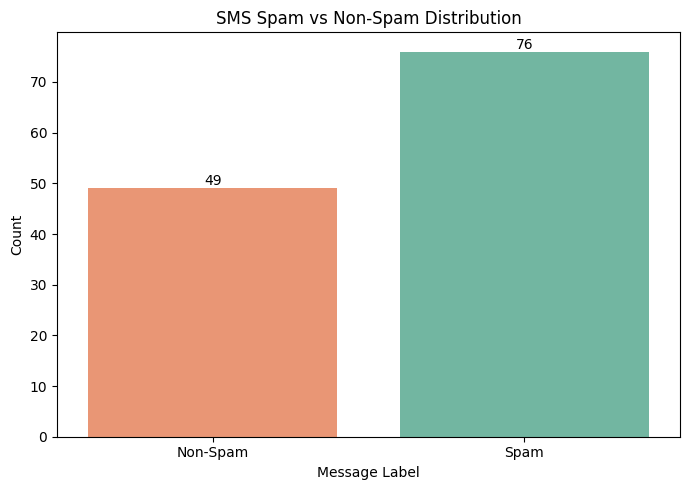


Class percentages:
Label
Spam        60.8
Non-Spam    39.2
Name: proportion, dtype: float64


In [ ]:
label_names = df["Label"].map({
    0: "Non-Spam",
    1: "Spam"
})

plt.figure(figsize=(7, 5))

ax = sns.countplot(
    x=label_names,
    hue=label_names,
    order=["Non-Spam", "Spam"],
    palette="Set2",
    legend=False
)

for bar in ax.patches:
    height = bar.get_height()
    ax.annotate(
        f"{int(height)}",
        (bar.get_x() + bar.get_width() / 2, height),
        ha="center",
        va="bottom"
    )

plt.title("SMS Spam vs Non-Spam Distribution")
plt.xlabel("Message Label")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

print("\nClass percentages:")
print((label_names.value_counts(normalize=True) * 100).round(2))

### Case Study 5: Text Preprocessing & Cleaning Pipeline

**Purpose:**
Raw SMS texts contain a lot of noise like hyperlinks, HTML tags, email addresses, and random whitespaces. Cleaning this noise helps our vectorizer focus only on meaningful text tokens.

**Key Steps:**
- We define a reusable function `clean_text` that converts text to lowercase.
- Uses regular expressions (`re.sub`) to scrub URLs, email addresses, and HTML tags.
- Extra spaces are normalized into a single space.
- Finally, we drop any messages that became completely empty after this cleaning process.

In [ ]:
def clean_text(text):
    text = str(text).lower()

    # URLs remove karo
    text = re.sub(
        r"https?://\S+|www\.\S+",
        " ",
        text
    )

    # Email addresses remove karo
    text = re.sub(
        r"\b[\w.+-]+@[\w.-]+\.[a-zA-Z]{2,}\b",
        " ",
        text
    )

    # HTML tags remove karo
    text = re.sub(
        r"<[^>]+>",
        " ",
        text
    )

    # Extra whitespace normalize karo
    text = re.sub(r"\s+", " ", text).strip()

    return text


df["Cleaned_Message"] = df["Message_body"].apply(clean_text)

# Cleaning ke baad empty messages check karo
df = df[df["Cleaned_Message"].str.strip() != ""].copy()

display(
    df[["Message_body", "Cleaned_Message", "Label"]].head(10)
)

print("Empty cleaned messages:",
      df["Cleaned_Message"].eq("").sum())

,Message_body,Cleaned_Message,Label
0,"UpgrdCentre Orange customer, you may now claim...","upgrdcentre orange customer, you may now claim...",1
1,"Loan for any purpose £500 - £75,000. Homeowner...","loan for any purpose £500 - £75,000. homeowner...",1
2,Congrats! Nokia 3650 video camera phone is you...,congrats! nokia 3650 video camera phone is you...,1
3,URGENT! Your Mobile number has been awarded wi...,urgent! your mobile number has been awarded wi...,1
4,Someone has contacted our dating service and e...,someone has contacted our dating service and e...,1
5,Send a logo 2 ur lover - 2 names joined by a h...,send a logo 2 ur lover - 2 names joined by a h...,1
6,FREE entry into our £250 weekly competition ju...,free entry into our £250 weekly competition ju...,1
7,100 dating service cal;l 09064012103 box334sk38ch,100 dating service cal;l 09064012103 box334sk38ch,1
8,FREE RINGTONE text FIRST to 87131 for a poly o...,free ringtone text first to 87131 for a poly o...,1
9,4mths half price Orange line rental & latest c...,4mths half price orange line rental & latest c...,1


Empty cleaned messages: 0


### Case Study 6: Train-Test Splitting (Stratified)

**Purpose:**
To split our dataset into separate training and testing subsets to evaluate generalization performance without data leakage.

**Key Steps:**
- We set `test_size=0.20`, devoting 80% of data to training and 20% to testing.
- We apply `stratify=y` which ensures that the ratio of Spam and Non-Spam in both training and testing datasets matches the original dataset's overall ratio. This is a crucial practice for maintaining class consistency.

In [ ]:
X = df["Cleaned_Message"]
y = df["Label"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Train samples:", len(X_train))
print("Test samples:", len(X_test))

print("\nTrain class distribution:")
print(y_train.value_counts())

print("\nTest class distribution:")
print(y_test.value_counts())

Train samples: 100
Test samples: 25

Train class distribution:
Label
1    61
0    39
Name: count, dtype: int64

Test class distribution:
Label
1    15
0    10
Name: count, dtype: int64


### Case Study 7: Scikit-Learn Pipeline Setup & Training

**Purpose:**
Constructing a robust, repeatable machine learning workflow using scikit-learn's `Pipeline` object.

**Key Components:**
1. **Feature Extraction (`TfidfVectorizer`):** Converts text data to numerical TF-IDF matrices. We use a combination of unigrams and bigrams (`ngram_range=(1,2)`), set `max_features=5000` to prevent dimensionality explosion, and enable `sublinear_tf` to scale word frequencies logarithmically.
2. **Classifier (`LogisticRegression`):** We use a simple, highly interpretable linear classifier. Crucially, we set `class_weight='balanced'` to offset any class distribution inequalities.

In [ ]:
model = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            lowercase=False,  # Already cleaned
            ngram_range=(1, 2),
            max_features=5000,
            sublinear_tf=True,
            strip_accents="unicode"
        )
    ),
    (
        "classifier",
        LogisticRegression(
            C=1.0,
            class_weight="balanced",
            max_iter=2000,
            random_state=42
        )
    )
])

model.fit(X_train, y_train)

print("Logistic Regression training completed!")

Logistic Regression training completed!


### Case Study 8: Model Evaluation & Performance Metrics

**Purpose:**
Evaluate the performance of our trained model on the unseen test dataset using standard classification metrics.

**Metrics Discussed:**
- **Accuracy:** The percentage of correct classifications.
- **Precision:** Out of all predicted spam messages, how many were actually spam. (Crucial to avoid filtering out legitimate emails).
- **Recall:** Out of all actual spam messages, how many did the model identify.
- **F1-Score:** Harmonic mean of precision and recall.

In [ ]:
y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

print(f"Accuracy : {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-Score : {f1:.4f}")

print("\nClassification Report:\n")

print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Non-Spam", "Spam"],
    zero_division=0
))

Accuracy : 0.9600 (96.00%)
Precision: 0.9375
Recall   : 1.0000
F1-Score : 0.9677

Classification Report:

              precision    recall  f1-score   support

    Non-Spam       1.00      0.90      0.95        10
        Spam       0.94      1.00      0.97        15

    accuracy                           0.96        25
   macro avg       0.97      0.95      0.96        25
weighted avg       0.96      0.96      0.96        25



### Case Study 9: Confusion Matrix Visualization

**Purpose:**
To visually inspect the exact count of True Positives, True Negatives, False Positives, and False Negatives.

**Key Insight:**
This matrix allows us to easily see if the model is confusing Non-Spam messages as Spam (Type I error) or failing to catch actual Spam (Type II error).

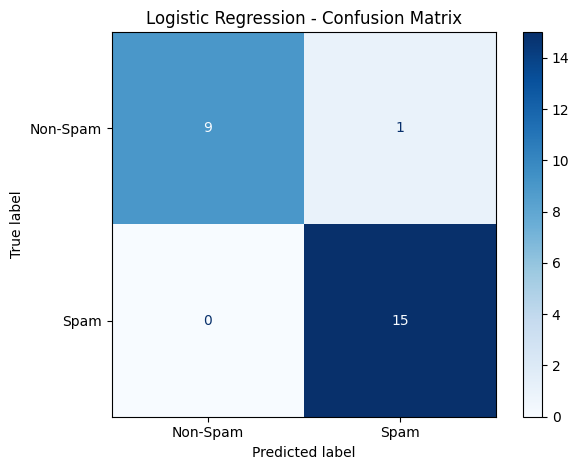

Rows = Actual labels
Columns = Predicted labels


In [ ]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=[0, 1]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Non-Spam", "Spam"]
)

disp.plot(values_format="d", cmap="Blues")

plt.title("Logistic Regression - Confusion Matrix")
plt.tight_layout()
plt.show()

print("Rows = Actual labels")
print("Columns = Predicted labels")

### Case Study 10: Receiver Operating Characteristic (ROC) & AUC Analysis

**Purpose:**
To analyze the diagnostic ability of our binary classifier across all possible classification thresholds.

**Key Metrics:**
- **ROC Curve:** Plots True Positive Rate (Sensitivity) vs False Positive Rate (1 - Specificity).
- **AUC (Area Under Curve):** A single metric evaluating how well the model distinguishes between classes. An AUC close to 1.0 (such as our ~0.993) represents exceptional predictive performance.

ROC-AUC Score: 0.9933
ROC-AUC Percentage: 99.33%


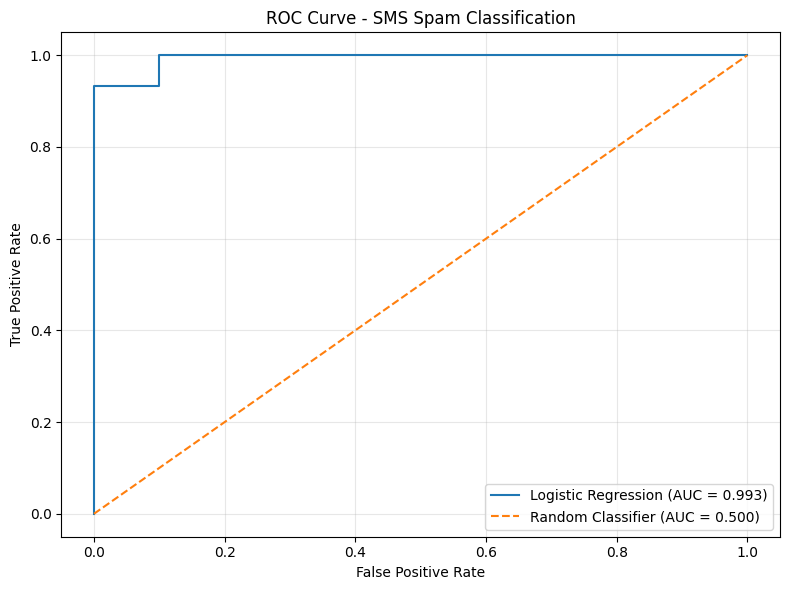

In [ ]:
# Class 1 = Spam
spam_probability = model.predict_proba(X_test)[:, 1]

roc_auc = roc_auc_score(
    y_test,
    spam_probability
)

fpr, tpr, thresholds = roc_curve(
    y_test,
    spam_probability
)

print(f"ROC-AUC Score: {roc_auc:.4f}")
print(f"ROC-AUC Percentage: {roc_auc * 100:.2f}%")

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"Logistic Regression (AUC = {roc_auc:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier (AUC = 0.500)"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - SMS Spam Classification")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Case Study 11: Exporting Model Artifacts

**Purpose:**
To serialize and save our trained pipeline (including vectorizer weights and logistic regression coefficients) and label dictionary for future runtime environments or API deployment.

**Implementation:**
We bundle the model pipeline and target labels inside a dictionary artifact and save it as a local `.joblib` file using the `joblib` library.

In [ ]:
artifact = {
    "pipeline": model,
    "label_mapping": {
        0: "Non-Spam",
        1: "Spam"
    }
}

joblib.dump(
    artifact,
    "sms_spam_logistic_regression.joblib"
)

print("Model saved successfully!")

Model saved successfully!


### Case Study 12: Inference Pipeline Verification

**Purpose:**
Simulating a real-world production test where a user provides a raw string, and the system dynamically cleans, predicts, and calculates the probability score.

**Implementation:**
- Loads the pre-trained model and variables from `.joblib`.
- Asks the user for input via `input()`.
- Runs the exact same `clean_text` process applied during training to prevent skew.
- Infers predicted label and the confidence probability score.

In [ ]:
# Saved pipeline load karo
saved_artifact = joblib.load(
    "sms_spam_logistic_regression.joblib"
)

loaded_model = saved_artifact["pipeline"]
label_mapping = saved_artifact["label_mapping"]

message = input("Enter an SMS message: ")

# Same cleaning function use karo
cleaned_message = clean_text(message)

if not cleaned_message:
    print("Please enter a valid SMS message.")
else:
    prediction = loaded_model.predict([cleaned_message])[0]
    probability = loaded_model.predict_proba([cleaned_message])[0]

    spam_index = list(
        loaded_model.named_steps["classifier"].classes_
    ).index(1)

    print("Predicted Label:", label_mapping[int(prediction)])
    print(f"Spam probability: {probability[spam_index] * 100:.2f}%")

Enter an SMS message: Hi, please call me when you reach home.
Predicted Label: Non-Spam
Spam probability: 46.12%
